Original Data:
   Weight_kg  Height_cm
0          5         30
1          7         35
2         10         40
3         25         60
4         30         65
5         35         70
6         60        100
7         70        110
8         80        120

Clustered Data:
   Weight_kg  Height_cm  Cluster
0          5         30        2
1          7         35        2
2         10         40        2
3         25         60        0
4         30         65        0
5         35         70        0
6         60        100        1
7         70        110        1
8         80        120        1


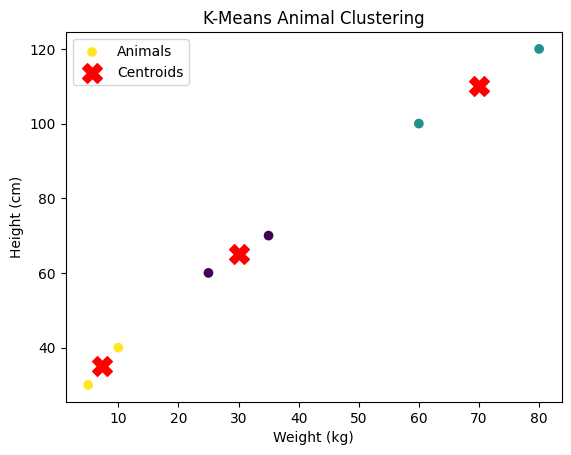

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Step 1: Create dataset
data = {
    'Weight_kg': [5, 7, 10, 25, 30, 35, 60, 70, 80],
    'Height_cm': [30, 35, 40, 60, 65, 70, 100, 110, 120]
}

X_animals = pd.DataFrame(data)

print("Original Data:")
print(X_animals)

# Step 2: Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_animals)

# Step 3: Apply K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# Step 4: Add cluster labels
X_animals['Cluster'] = kmeans.labels_

print("\nClustered Data:")
print(X_animals)

# Step 5: Plot clusters
plt.scatter(
    X_animals['Weight_kg'],
    X_animals['Height_cm'],
    c=X_animals['Cluster'],
    cmap='viridis',
    label='Animals'
)

# Plot centroids in original scale
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.xlabel("Weight (kg)")
plt.ylabel("Height (cm)")
plt.title("K-Means Animal Clustering")
plt.legend()
plt.show()


Student Data:
   Study_Hours_Week  Sleep_Hours_Night
0                 5                  8
1                 8                  7
2                10                  8
3                15                  6
4                18                  7
5                20                  5
6                25                  6
7                28                  5


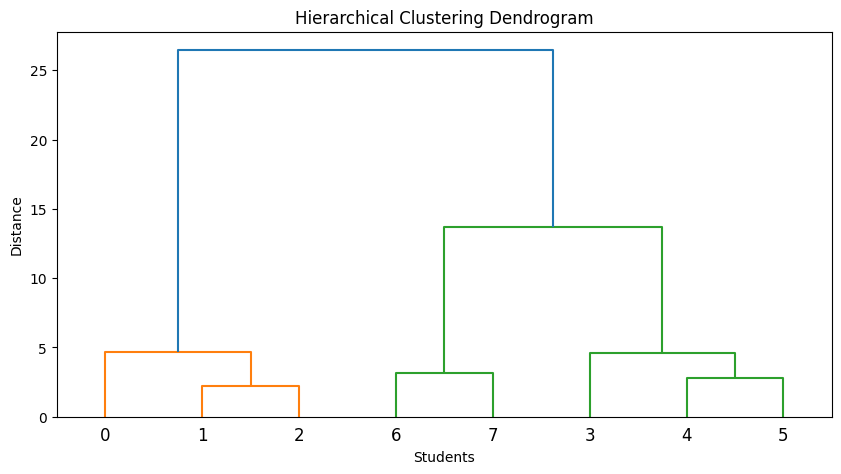

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# Step 1: Create dataset
data = {
    'Study_Hours_Week': [5, 8, 10, 15, 18, 20, 25, 28],
    'Sleep_Hours_Night': [8, 7, 8, 6, 7, 5, 6, 5]
}

X_students = pd.DataFrame(data)

print("Student Data:")
print(X_students)

# Step 2: Perform Hierarchical Clustering
linked = linkage(X_students, method='ward')

# Step 3: Display dendrogram
plt.figure(figsize=(10, 5))

dendrogram(
    linked,
    labels=X_students.index.tolist()
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Students")
plt.ylabel("Distance")
plt.show()
